In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar `creditsight` sin instalarlo: el código vive en ejemplo/src
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 05 · Torneo de modelos

Objetivo: elegir **uno o dos finalistas** para optimizar, con evidencia y sin tocar la prueba. Un
torneo bien hecho tiene tres reglas:

1. **Mismos datos y misma validación para todos** (5 pliegues, por cliente, las mismas semillas).
2. **Un punto de referencia** que cualquier modelo serio debe vencer (el baseline).
3. **Mirar la variabilidad**, no solo el promedio: una diferencia menor que lo que varía entre
   pliegues no es una victoria.

| Candidato | Por qué está |
|---|---|
| Baseline (clase más frecuente) | Piso: lo que se logra sin aprender nada |
| Regresión logística | Interpretable; los reguladores en crédito la entienden y la prefieren |
| Random forest | Ensamble de árboles independientes: robusto, pocos supuestos |
| LightGBM | Boosting rápido y muy competitivo en datos tabulares |
| XGBoost | Boosting de referencia; vale compararlo con LightGBM |

Todos usan la **misma configuración de variables** decidida en la etapa 4 (base + `Credit_Mix`).

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from creditsight.config import PROCESSED_DIR, REPORTS_DIR, TARGET
from creditsight.data.split import group_cv
from creditsight.models.train import build_pipeline, candidates, encode_target, evaluate_folds

train = joblib.load(PROCESSED_DIR / "train.joblib")
X, y = train.drop(columns=[TARGET]), encode_target(train[TARGET])
cv = group_cv(5)
print(f"{len(X):,} filas de entrenamiento · 5 pliegues por cliente · la prueba sigue cerrada")

80,000 filas de entrenamiento · 5 pliegues por cliente · la prueba sigue cerrada


## Correr el torneo

Cada candidato se entrena y valida en los 5 pliegues. Guardamos **cada pliegue** (no solo el
promedio) para poder comparar de a pares.

In [3]:
folds = {}
for name, (model, scale) in candidates().items():
    folds[name] = evaluate_folds(build_pipeline(model, scale=scale), X, y, cv)
    f = folds[name]
    print(f"{name:32s} costo = {f.cost.mean():.4f} ± {f.cost.std():.4f}   ({f.fit_seconds.mean():.0f} s por ajuste)")

baseline (clase más frecuente)   costo = 1.0494 ± 0.0003   (1 s por ajuste)


regresión logística              costo = 0.5528 ± 0.0139   (4 s por ajuste)


random forest                    costo = 0.4820 ± 0.0077   (12 s por ajuste)


lightgbm                         costo = 0.4894 ± 0.0075   (6 s por ajuste)


xgboost                          costo = 0.4900 ± 0.0080   (11 s por ajuste)


In [4]:
summary = pd.DataFrame({
    "costo": {n: f.cost.mean() for n, f in folds.items()},
    "± pliegues": {n: f.cost.std() for n, f in folds.items()},
    "costo (clase más probable)": {n: f.cost_argmax.mean() for n, f in folds.items()},
    "log loss": {n: f.log_loss.mean() for n, f in folds.items()},
    "F1 macro": {n: f.macro_f1.mean() for n, f in folds.items()},
    "recall Poor": {n: f.recall_poor.mean() for n, f in folds.items()},
    "segundos por ajuste": {n: f.fit_seconds.mean() for n, f in folds.items()},
}).sort_values("costo")
summary.to_csv(REPORTS_DIR / "05_torneo_tabla.csv")
summary.round(4)

,costo,± pliegues,costo (clase más probable),log loss,F1 macro,recall Poor,segundos por ajuste
random forest,0.4820,0.0077,0.7869,0.6672,0.5002,0.8237,11.7196
lightgbm,0.4894,0.0075,0.7722,0.6686,0.5442,0.8075,5.6519
xgboost,0.4900,0.0080,0.7760,0.6687,0.5464,0.8072,10.6936
regresión logística,0.5528,0.0139,0.9252,0.7339,0.4549,0.7743,3.7725
baseline (clase más frecuente),1.0494,0.0003,1.0494,16.8531,0.2316,0.0000,0.9786


## Leer el resultado

Dos cosas que se pierden fácilmente:

- **La columna "costo (clase más probable)" frente a "costo"** muestra el valor de la regla de decisión
  de negocio (menor costo esperado): reduce el costo de **todos** los modelos con probabilidades útiles.
- **Un modelo que no aprende (baseline) cuesta lo mismo con cualquier regla**: no tiene probabilidades
  que explotar.

Veamos la variabilidad, que es lo que dice si las diferencias son reales.

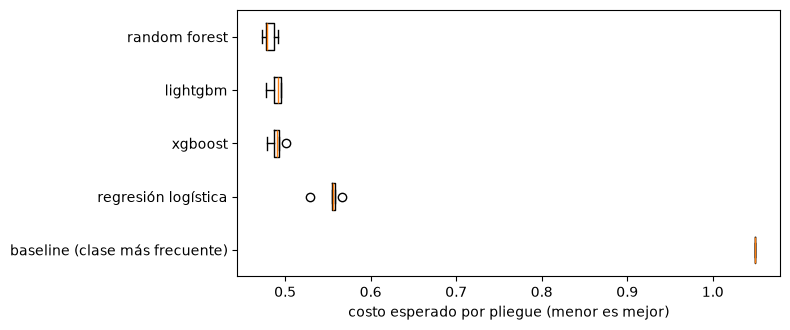

In [5]:
order = summary.index.tolist()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([folds[n].cost for n in order], vert=False, tick_labels=order, widths=0.5)
ax.invert_yaxis(); ax.set_xlabel("costo esperado por pliegue (menor es mejor)")
plt.tight_layout(); plt.show()

## ¿La diferencia entre los mejores es real?

Los dos o tres primeros se parecen. Como todos se evaluaron **en los mismos pliegues**, podemos
comparar pliegue a pliegue (comparación pareada): ¿gana siempre el mismo?

In [6]:
top = order[:3]
pairs = []
for i in range(len(top)):
    for j in range(i + 1, len(top)):
        diff = folds[top[j]].cost - folds[top[i]].cost  # positivo: top[i] mejor
        pairs.append({
            "mejor": top[i], "contra": top[j],
            "diferencia media de costo": diff.mean(),
            "pliegues que gana": f"{(diff > 0).sum()} de {len(diff)}",
            "diferencia / ruido": diff.mean() / diff.std(ddof=1) if diff.std(ddof=1) > 0 else np.inf,
        })
pd.DataFrame(pairs).round(4)

,mejor,contra,diferencia media de costo,pliegues que gana,diferencia / ruido
0,random forest,lightgbm,0.0075,5 de 5,1.4351
1,random forest,xgboost,0.0080,5 de 5,2.2430
2,lightgbm,xgboost,0.0005,2 de 5,0.1716


Una diferencia que **gana en todos los pliegues** y es varias veces mayor que su ruido es
consistente; una que gana en 3 de 5 con ruido mayor que la diferencia es un empate práctico.

## ¿Cuánto vale la diferencia en dinero?

El costo está en unidades relativas. Para el negocio, lo útil es traducirlo a un volumen
concreto. Con **100.000 decisiones al mes**:

In [7]:
monthly = 100_000
best = summary.index[0]
rows = []
for name in summary.index:
    rows.append({
        "modelo": name,
        "costo por decisión": summary.loc[name, "costo"],
        "costo mensual (unidades)": summary.loc[name, "costo"] * monthly,
        "ahorro vs. baseline": (summary.loc["baseline (clase más frecuente)", "costo"] - summary.loc[name, "costo"]) * monthly,
        "extra vs. el mejor": (summary.loc[name, "costo"] - summary.loc[best, "costo"]) * monthly,
    })
money = pd.DataFrame(rows).set_index("modelo")
money.style.format({"costo por decisión": "{:.3f}", **{c: "{:,.0f}" for c in money.columns[1:]}})

,costo por decisión,costo mensual (unidades),ahorro vs. baseline,extra vs. el mejor
modelo,,,,
random forest,0.482,"48,196","56,741",0
lightgbm,0.489,"48,945","55,993",749
xgboost,0.490,"48,997","55,940",801
regresión logística,0.553,"55,285","49,653","7,089"
baseline (clase más frecuente),1.049,"104,938",0,"56,741"


## Decisión

Lo que muestran los números:

- **Random forest gana al boosting en los 5 pliegues** (diferencia de 1,4 a 2,2 veces el ruido): es
  la ventaja más consistente de la tabla, aunque pequeña en dinero. Cuesta unas 750–800 unidades
  mensuales menos que LightGBM y XGBoost por cada 100.000 decisiones.
- **LightGBM y XGBoost empatan** (menos de 0,2 veces el ruido; cada uno gana en 2 y 3 pliegues). Con
  empate, gana el más rápido y simple de operar: **LightGBM**.
- **La regresión logística cuesta ~7.000 unidades mensuales más** que el mejor. Es la referencia
  interpretable: si el equipo de riesgo exige un modelo explicable por regulación, esa diferencia
  es el precio, y es una decisión de negocio, no solo técnica.
- **Baseline:** todos los modelos lo superan con holgura (ahorro de ~50.000–57.000 unidades al mes).

**Finalistas para la optimización: random forest y LightGBM.** XGBoost queda fuera por empate con
LightGBM y mayor tiempo de ajuste.

### Una advertencia sobre la métrica

Random forest logra el menor costo siendo el **más conservador**: tiene el mayor recall de `Poor`
(0,82) y el menor F1 macro (0,50). Para esta matriz de costos eso es lo correcto: prefiere marcar de
más a un cliente como riesgoso (error barato) que dejar pasar a uno riesgoso (error caro). Pero
implica **más casos para el analista**. La carga de revisión es un efecto que el costo no ve y que
se mide en la etapa de validación.

> **El torneo elige finalistas, no un campeón definitivo.** La optimización puede cambiar el orden,
> y solo la prueba final (etapa 7) dice qué tan bueno es el modelo elegido.

**Siguiente:** `06_optimizacion.ipynb`, con seguimiento de cada ejecución en MLflow.